In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import pandas as pd

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

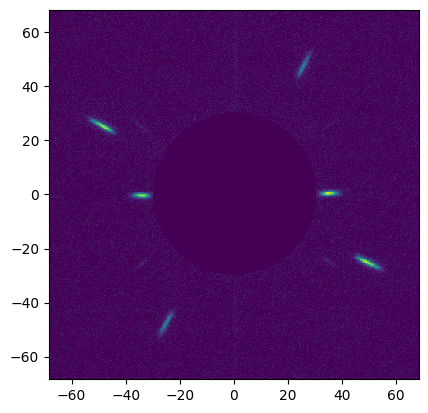

In [2]:
fieldcube = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_lab_fields_i.fits')
img = fieldcube[0]
imshow_field(img)

In [3]:
def moving_average(a, n=10):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+1*std) & (data > mean-2*std)) #the indicies of numbers we're NOT rejecting
    return data[indices]


In [4]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [5]:
ADC.set_control_mtx(np.array([0.21178766, 0.19275196]))
disps = np.zeros(len(fieldcube))
commands = []
speckle_angles = []
pointings = []

for i, field in enumerate(fieldcube):
    ADC.set_psf(field)
    angles = ADC.find_speckle_angles2()
    pairs = ADC.speckle_pairs(angles)
    speckle_angles.append(angles)
    pointings.append(pairs)
    commands.append(ADC.calculate_command(pairs))

pointings = np.array(pointings)
commands = np.array(commands)

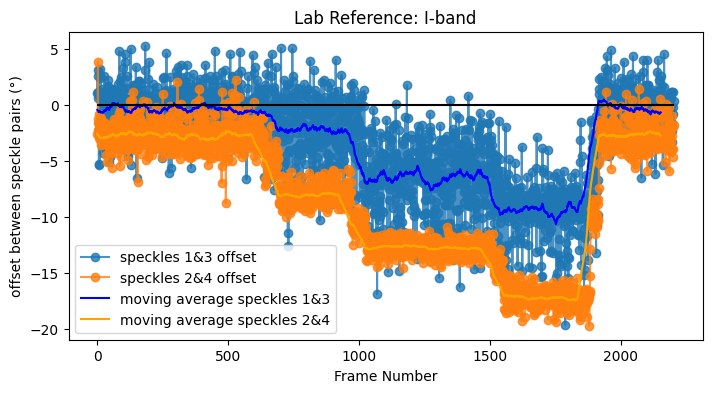

In [9]:
avg1 = moving_average(pointings[:,0],n=50)
avg2 = moving_average(pointings[:,1],n=50)

plt.figure(figsize=(18,4))
plt.subplot(1,2,1)
plt.plot(pointings[:,0],'-o',label='speckles 1&3 offset',alpha=0.8)
plt.plot(pointings[:,1],'-o',label='speckles 2&4 offset',alpha=0.8)
plt.plot(avg1,'-',label='moving average speckles 1&3',color='blue')
plt.plot(avg2,'-',label='moving average speckles 2&4',color='orange')
plt.hlines(0,0,len(commands),'black')
plt.xlabel('Frame Number')
plt.ylabel('offset between speckle pairs (°)')
plt.title('Lab Reference: I-band')
plt.legend()

In [7]:
# firsts = pointings[0:500,:]
# data = pd.Series(firsts[:,0])

# #rolling std
# rolled50 = data.rolling(window=50).std()
# rolled100 = data.rolling(window=100).std()
# rolled10 = data.rolling(window=10).std()

# plt.plot(rolled10,'o-',alpha=0.8,label='10')
# plt.plot(rolled50,'o-',alpha=0.8,label='50')
# plt.plot(rolled100,'o-',alpha=0.8,label='100')
# plt.grid()
# plt.legend()

mean: -0.3186509024492847
mean: -2.76156690635508
std: 1.8273187589452184
std: 1.2544418240976278


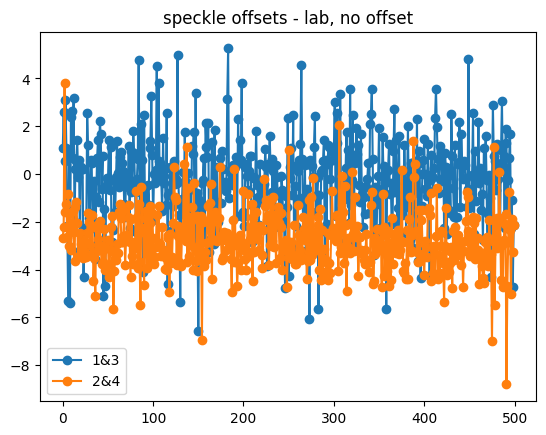

In [10]:
firsts = pointings[0:500,:]
plt.plot(firsts[:,0],'o-',label='1&3')
plt.plot(firsts[:,1],'o-',label='2&4')

print(f'mean: {np.mean(firsts[:,0])}')
print(f'mean: {np.mean(firsts[:,1])}')

print(f'std: {np.std(firsts[:,0])}')
print(f'std: {np.std(firsts[:,1])}')

plt.title('speckle offsets - lab, no offset')
plt.legend()
plt.show()